In [0]:
# 03_analisis_netflix
## 3.1 Catálogo, esquema y tablas utilizadas

In [0]:
catalogo = spark.catalog.currentCatalog()
esquema  = spark.catalog.currentDatabase()
RUTA = "/Volumes/workspace/default/netflix"   # ajustar si es otra ruta

T_NETFLIX = f"{catalogo}.{esquema}.netflix_clean"
T_MR      = f"{catalogo}.{esquema}.mapreduce_actores"

print("Catálogo:", catalogo)
print("Esquema :", esquema)
print("Tabla 1 :", T_NETFLIX)
print("Tabla 2 :", T_MR)

Catálogo: workspace
Esquema : default
Tabla 1 : workspace.default.netflix_clean
Tabla 2 : workspace.default.mapreduce_actores


In [0]:
def leer_csv(nombre):
    return (spark.read
            .option("header", True)       # cabecera como nombres de columna
            .option("inferSchema", True)
            .option("quote", '"')
            .option("escape", '"')        # comas dentro de comillas
            .option("multiLine", True)
            .csv(f"{RUTA}/{nombre}"))

leer_csv("netflix_clean.csv").write.mode("overwrite").saveAsTable(T_NETFLIX)
leer_csv("mapreduce_actores.csv").write.mode("overwrite").saveAsTable(T_MR)

In [0]:
nf = spark.table(T_NETFLIX)
mr = spark.table(T_MR)

# 1. Cabeceras como nombres de columnas
print("Columnas netflix_clean :", nf.columns)
print("Columnas mapreduce     :", mr.columns)

# 2. Comas dentro de campos: no debe haber columnas desplazadas
print("type distintos:", [r[0] for r in nf.select("type").distinct().collect()])
print("Filas con show_id nulo:", nf.filter("show_id IS NULL").count())
print("Filas con release_year nulo:", nf.filter("release_year IS NULL").count())
display(nf.filter("cast LIKE '%,%'").select("title", "cast").limit(3))

# 3. Registros netflix_clean vs Tabla 1 (8807)
n_nf = nf.count()
print("Registros netflix_clean:", n_nf, "| Tabla 1: 8807 | Coincide:", n_nf == 8807)

# 4. Actores mapreduce_actores vs filas del CSV exportado (líneas - cabecera)
n_mr = mr.count()
filas_csv = spark.read.text(f"{RUTA}/mapreduce_actores.csv").count() - 1
print("Actores en la tabla:", n_mr, "| Filas del CSV:", filas_csv, "| Coincide:", n_mr == filas_csv)

Columnas netflix_clean : ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description', 'duration_min']
Columnas mapreduce     : ['actor', 'cantidad_titulos']
type distintos: ['Movie', 'TV Show']
Filas con show_id nulo: 0
Filas con release_year nulo: 0


title,cast
Blood & Water,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno Greeff, Xolile Tshabalala, Getmore Sithole, Cindy Mahlangu, Ryle De Morny, Greteli Fincham, Sello Maake Ka-Ncube, Odwa Gwanya, Mekaila Mathys, Sandi Schultz, Duane Williams, Shamilla Miller, Patrick Mofokeng"
Ganglands,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert Van Rampelberg, Bakary Diombera"
Kota Factory,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Arun Kumar"


Registros netflix_clean: 8807 | Tabla 1: 8807 | Coincide: True
Actores en la tabla: 36439 | Filas del CSV: 36439 | Coincide: True


In [0]:
display(spark.table(T_NETFLIX).limit(5))

show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_min
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,null,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable.",90
s2,TV Show,Blood & Water,null,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno Greeff, Xolile Tshabalala, Getmore Sithole, Cindy Mahlangu, Ryle De Morny, Greteli Fincham, Sello Maake Ka-Ncube, Odwa Gwanya, Mekaila Mathys, Sandi Schultz, Duane Williams, Shamilla Miller, Patrick Mofokeng",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.",null
s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert Van Rampelberg, Bakary Diombera",null,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into a violent and deadly turf war.",null
s4,TV Show,Jailbirds New Orleans,null,null,null,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans on this gritty reality series.",null
s5,TV Show,Kota Factory,null,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Arun Kumar",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student and his friends navigate campus life.",null


In [0]:
display(spark.table(T_MR).orderBy("cantidad_titulos", ascending=False).limit(5))

actor,cantidad_titulos
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32


In [0]:
%sql
SELECT 
    type AS tipo, 
    COUNT(DISTINCT show_id) AS cantidad_titulos
FROM netflix_clean
WHERE type IN ('Movie', 'TV Show')
GROUP BY type
ORDER BY type ASC;

tipo,cantidad_titulos
Movie,6131
TV Show,2676


In [0]:
from pyspark.sql.functions import col, countDistinct

df_analisis_a = (
    spark.table(T_NETFLIX)
    .filter(col("type").isin(["Movie", "TV Show"]))
    .groupBy("type")
    .agg(countDistinct("show_id").alias("cantidad_titulos"))
    .withColumnRenamed("type", "tipo")
    .orderBy("tipo")
)
display(df_analisis_a)

tipo,cantidad_titulos
Movie,6131
TV Show,2676


In [0]:
%sql
SELECT 
    TRIM(pais) AS pais,
    COUNT(DISTINCT show_id) AS cantidad_peliculas,
    ROUND(AVG(CAST(duration_min AS DOUBLE)), 2) AS duracion_promedio_min
FROM netflix_clean
LATERAL VIEW EXPLODE(SPLIT(country, ',')) AS pais
WHERE type = 'Movie' 
  AND duration_min IS NOT NULL 
  AND CAST(duration_min AS INT) > 0
  AND country IS NOT NULL 
  AND TRIM(pais) != ''
GROUP BY TRIM(pais)
ORDER BY cantidad_peliculas DESC, pais ASC;

pais,cantidad_peliculas,duracion_promedio_min
United States,2749,93.75
India,962,125.91
United Kingdom,534,98.76
Canada,319,91.15
France,303,100.97
Germany,182,103.01
Spain,171,101.1
Japan,119,98.85
China,114,104.46
Mexico,111,90.6


In [0]:
%sql
SELECT 
    TRIM(actor) AS actor, 
    COUNT(DISTINCT show_id) AS cantidad_titulos
FROM netflix_clean
LATERAL VIEW EXPLODE(SPLIT(cast, ',')) AS actor
WHERE cast IS NOT NULL AND TRIM(actor) != ''
GROUP BY TRIM(actor)
ORDER BY cantidad_titulos DESC, actor ASC;

actor,cantidad_titulos
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32
Rupa Bhimani,31
Akshay Kumar,30
Om Puri,30
Yuki Kaji,29
Amitabh Bachchan,28


In [0]:
from pyspark.sql.functions import split, explode, trim

df_actores_pyspark = (
    spark.table(T_NETFLIX)
    .filter(col("cast").isNotNull() & (trim(col("cast")) != ""))
    .withColumn("actor", explode(split(col("cast"), ",")))
    .withColumn("actor", trim(col("actor")))
    .filter(col("actor") != "")
    .groupBy("actor")
    .agg(countDistinct("show_id").alias("cantidad_titulos"))
    .orderBy(col("cantidad_titulos").desc(), col("actor").asc())
)
display(df_actores_pyspark)

actor,cantidad_titulos
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32
Rupa Bhimani,31
Akshay Kumar,30
Om Puri,30
Yuki Kaji,29
Amitabh Bachchan,28


In [0]:
%sql
SELECT 
    TRIM(pais) AS pais,
    COUNT(DISTINCT show_id) AS cantidad_peliculas,
    ROUND(AVG(CAST(duration_min AS DOUBLE)), 2) AS duracion_promedio_min
FROM netflix_clean
LATERAL VIEW EXPLODE(SPLIT(country, ',')) AS pais
WHERE type = 'Movie' 
  AND duration_min IS NOT NULL 
  AND CAST(duration_min AS INT) > 0
  AND country IS NOT NULL 
  AND TRIM(pais) != ''
GROUP BY TRIM(pais)
ORDER BY cantidad_peliculas DESC, pais ASC;

pais,cantidad_peliculas,duracion_promedio_min
United States,2749,93.75
India,962,125.91
United Kingdom,534,98.76
Canada,319,91.15
France,303,100.97
Germany,182,103.01
Spain,171,101.1
Japan,119,98.85
China,114,104.46
Mexico,111,90.6


In [0]:
from pyspark.sql.functions import round as spark_round, avg

df_analisis_c = (
    spark.table(T_NETFLIX)
    .filter((col("type") == "Movie") & col("duration_min").isNotNull() & (col("duration_min") > 0) & col("country").isNotNull())
    .withColumn("pais", explode(split(col("country"), ",")))
    .withColumn("pais", trim(col("pais")))
    .filter(col("pais") != "")
    .groupBy("pais")
    .agg(
        countDistinct("show_id").alias("cantidad_peliculas"),
        spark_round(avg("duration_min"), 2).alias("duracion_promedio_min")
    )
    .orderBy(col("cantidad_peliculas").desc(), col("pais").asc())
)
display(df_analisis_c)

pais,cantidad_peliculas,duracion_promedio_min
United States,2749,93.75
India,962,125.91
United Kingdom,534,98.76
Canada,319,91.15
France,303,100.97
Germany,182,103.01
Spain,171,101.1
Japan,119,98.85
China,114,104.46
Mexico,111,90.6


In [0]:
%sql
SELECT 
    type AS tipo, 
    COUNT(DISTINCT show_id) AS cantidad_titulos
FROM netflix_clean
WHERE type IN ('Movie', 'TV Show')
GROUP BY type
ORDER BY type ASC;

tipo,cantidad_titulos
Movie,6131
TV Show,2676


In [0]:
from pyspark.sql.functions import col, countDistinct

df_analisis_a = (
    spark.table(T_NETFLIX)
    .filter(col("type").isin(["Movie", "TV Show"]))
    .groupBy("type")
    .agg(countDistinct("show_id").alias("cantidad_titulos"))
    .withColumnRenamed("type", "tipo")
    .orderBy("tipo")
)
display(df_analisis_a)

tipo,cantidad_titulos
Movie,6131
TV Show,2676


In [0]:
df_sql_a = spark.sql(f"SELECT type AS tipo, COUNT(DISTINCT show_id) AS cantidad_titulos FROM {T_NETFLIX} WHERE type IN ('Movie', 'TV Show') GROUP BY type")

comp_a = df_sql_a.join(df_analisis_a, on="tipo", how="full_outer") \
    .select(
        col("tipo"),
        df_sql_a.cantidad_titulos.alias("sql_cnt"),
        df_analisis_a.cantidad_titulos.alias("spark_cnt")
    )

diff_a = comp_a.filter((col("sql_cnt") != col("spark_cnt")) | col("sql_cnt").isNull() | col("spark_cnt").isNull())
print(f"Filas SQL: {df_sql_a.count()} | Filas PySpark: {df_analisis_a.count()} | Diferencias: {diff_a.count()}")

Filas SQL: 2 | Filas PySpark: 2 | Diferencias: 0


In [0]:
%sql
SELECT 
    TRIM(actor) AS actor, 
    COUNT(DISTINCT show_id) AS cantidad_titulos
FROM netflix_clean
LATERAL VIEW EXPLODE(SPLIT(cast, ',')) AS actor
WHERE cast IS NOT NULL AND TRIM(actor) != ''
GROUP BY TRIM(actor)
ORDER BY cantidad_titulos DESC, actor ASC;

actor,cantidad_titulos
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32
Rupa Bhimani,31
Akshay Kumar,30
Om Puri,30
Yuki Kaji,29
Amitabh Bachchan,28


In [0]:
from pyspark.sql.functions import split, explode, trim

df_actores_pyspark = (
    spark.table(T_NETFLIX)
    .filter(col("cast").isNotNull() & (trim(col("cast")) != ""))
    .withColumn("actor", explode(split(col("cast"), ",")))
    .withColumn("actor", trim(col("actor")))
    .filter(col("actor") != "")
    .groupBy("actor")
    .agg(countDistinct("show_id").alias("cantidad_titulos"))
    .orderBy(col("cantidad_titulos").desc(), col("actor").asc())
)
display(df_actores_pyspark)

actor,cantidad_titulos
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32
Rupa Bhimani,31
Akshay Kumar,30
Om Puri,30
Yuki Kaji,29
Amitabh Bachchan,28


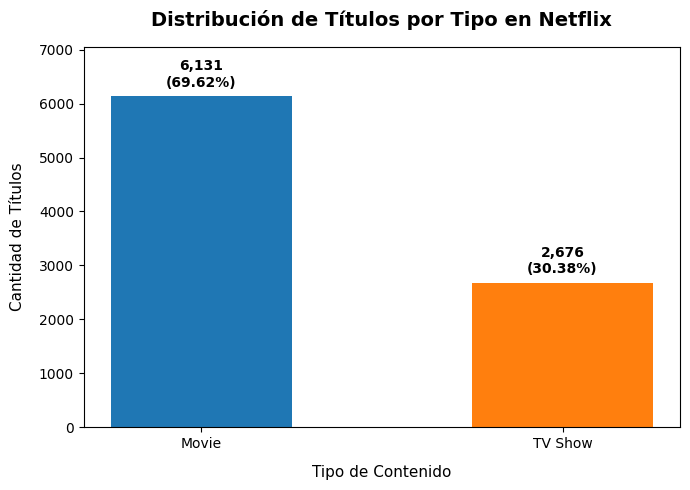

In [0]:
import matplotlib.pyplot as plt

# Obtener datos de PySpark
df_tipo = spark.table(T_NETFLIX) \
    .filter(col("type").isin(["Movie", "TV Show"])) \
    .groupBy("type") \
    .agg(countDistinct("show_id").alias("cantidad")) \
    .orderBy("type").toPandas()

total_titulos = df_tipo["cantidad"].sum()
tipos = df_tipo["type"].tolist()
cantidades = df_tipo["cantidad"].tolist()
porcentajes = [(c / total_titulos) * 100 for c in cantidades]

# Crear gráfico
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(tipos, cantidades, color=['#1f77b4', '#ff7f0e'], width=0.5)

ax.set_title("Distribución de Títulos por Tipo en Netflix", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Tipo de Contenido", fontsize=11, labelpad=10)
ax.set_ylabel("Cantidad de Títulos", fontsize=11, labelpad=10)
ax.set_ylim(0, max(cantidades) * 1.15)

# Etiquetas numéricas y porcentaje sobre cada barra
for bar, cant, pct in zip(bars, cantidades, porcentajes):
    height = bar.get_height()
    ax.annotate(f"{cant:,}\n({pct:.2f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

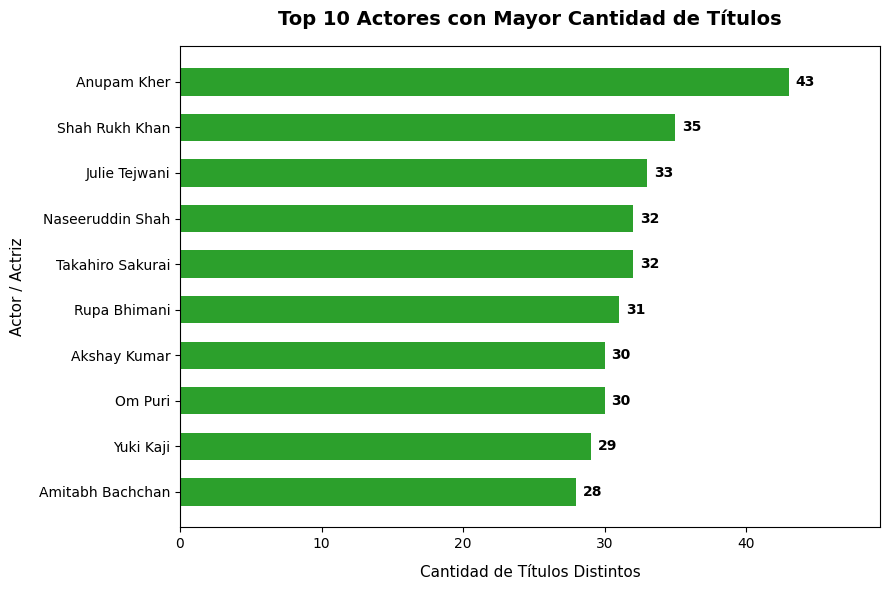

In [0]:
import matplotlib.pyplot as plt

# Obtener datos de PySpark
df_top_actores = df_actores_pyspark.limit(10).toPandas()
df_top_actores = df_top_actores.sort_values(by=["cantidad_titulos", "actor"], ascending=[True, False])

actores = df_top_actores["actor"].tolist()
cantidades = df_top_actores["cantidad_titulos"].tolist()

# Crear gráfico
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(actores, cantidades, color='#2ca02c', height=0.6)

ax.set_title("Top 10 Actores con Mayor Cantidad de Títulos", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Cantidad de Títulos Distintos", fontsize=11, labelpad=10)
ax.set_ylabel("Actor / Actriz", fontsize=11, labelpad=10)
ax.set_xlim(0, max(cantidades) * 1.15)

# Etiquetas numéricas al final de cada barra
for bar, cant in zip(bars, cantidades):
    width = bar.get_width()
    ax.annotate(f"{cant}",
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0),
                textcoords="offset points",
                ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [0]:
from pyspark.sql.functions import col, split, explode, trim, countDistinct, avg, round as spark_round

# 1. Procesar datos para la Tabla 6 (Top 10 países con más películas)
df_tabla_6 = (
    spark.table(T_NETFLIX)
    .filter(
        (col("type") == "Movie") & 
        col("duration_min").isNotNull() & 
        (col("duration_min") > 0) & 
        col("country").isNotNull()
    )
    .withColumn("pais", explode(split(col("country"), ",")))
    .withColumn("pais", trim(col("pais")))
    .filter(col("pais") != "")
    .groupBy("pais")
    .agg(
        countDistinct("show_id").alias("cantidad_peliculas"),
        spark_round(avg("duration_min"), 2).alias("duracion_promedio_min")
    )
    .orderBy(col("cantidad_peliculas").desc(), col("pais").asc())
    .limit(10)
)

# 2. Visualización en la interfaz de Databricks
display(df_tabla_6)

# 3. Formato impreso tipo tabla para la consola / salida del notebook
print("Tabla 6. Duración de películas por país")
print("-" * 65)
print(f"{'País':<20} | {'Películas Utilizadas':<22} | {'Promedio (min)':<15}")
print("-" * 65)
for row in df_tabla_6.collect():
    print(f"{row['pais']:<20} | {row['cantidad_peliculas']:<22} | {row['duracion_promedio_min']:<15.2f}")
print("-" * 65)

pais,cantidad_peliculas,duracion_promedio_min
United States,2749,93.75
India,962,125.91
United Kingdom,534,98.76
Canada,319,91.15
France,303,100.97
Germany,182,103.01
Spain,171,101.1
Japan,119,98.85
China,114,104.46
Mexico,111,90.6


Tabla 6. Duración de películas por país
-----------------------------------------------------------------
País                 | Películas Utilizadas   | Promedio (min) 
-----------------------------------------------------------------
United States        | 2749                   | 93.75          
India                | 962                    | 125.91         
United Kingdom       | 534                    | 98.76          
Canada               | 319                    | 91.15          
France               | 303                    | 100.97         
Germany              | 182                    | 103.01         
Spain                | 171                    | 101.10         
Japan                | 119                    | 98.85          
China                | 114                    | 104.46         
Mexico               | 111                    | 90.60          
-----------------------------------------------------------------


In [0]:
%sql
SELECT
    TRIM(pais) AS pais,
    COUNT(DISTINCT show_id) AS cantidad_peliculas,
    ROUND(AVG(CAST(duration_min AS DOUBLE)), 2) AS duracion_promedio_min
FROM netflix_clean
LATERAL VIEW EXPLODE(SPLIT(country, ',')) AS pais
WHERE type = 'Movie'
  AND duration_min IS NOT NULL
  AND CAST(duration_min AS INT) > 0
  AND country IS NOT NULL
  AND TRIM(pais) != ''
GROUP BY TRIM(pais)
ORDER BY cantidad_peliculas DESC, pais ASC
LIMIT 10;

pais,cantidad_peliculas,duracion_promedio_min
United States,2749,93.75
India,962,125.91
United Kingdom,534,98.76
Canada,319,91.15
France,303,100.97
Germany,182,103.01
Spain,171,101.1
Japan,119,98.85
China,114,104.46
Mexico,111,90.6


In [0]:
from pyspark.sql.functions import col, split, explode, trim, countDistinct, avg, round as spark_round

df_analisis_c = (
    spark.table(T_NETFLIX)
    .filter(
        (col("type") == "Movie") & 
        col("duration_min").isNotNull() & 
        (col("duration_min") > 0) & 
        col("country").isNotNull()
    )
    .withColumn("pais", explode(split(col("country"), ",")))
    .withColumn("pais", trim(col("pais")))
    .filter(col("pais") != "")
    .groupBy("pais")
    .agg(
        countDistinct("show_id").alias("cantidad_peliculas"),
        spark_round(avg("duration_min"), 2).alias("duracion_promedio_min")
    )
    .orderBy(col("cantidad_peliculas").desc(), col("pais").asc())
    .limit(10)
)

display(df_analisis_c)

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-6940438917598737>, line 4
      1 from pyspark.sql.functions import col, split, explode, trim, countDistinct, avg, round as spark_round
      3 df_analisis_c = (
----> 4     spark.table(T_NETFLIX)
      5     .filter(
      6         (col("type") == "Movie") & 
      7         col("duration_min").isNotNull() & 
      8         (col("duration_min") > 0) & 
      9         col("country").isNotNull()
     10     )
     11     .withColumn("pais", explode(split(col("country"), ",")))
     12     .withColumn("pais", trim(col("pais")))
     13     .filter(col("pais") != "")
     14     .groupBy("pais")
     15     .agg(
     16         countDistinct("show_id").alias("cantidad_peliculas"),
     17         spark_round(avg("duration_min"), 2).alias("duracion_promedio_min")
     18     )
     19     .orderBy(col("cantidad_peliculas")